# 04. BayesA — у каждого маркера своя дисперсия

В BRR одна дисперсия σ²_β на все маркеры, поэтому все эффекты стягиваются
одинаково. BayesA (Meuwissen et al., 2001) даёт каждому маркеру свою
дисперсию:

$$\beta_j \mid \sigma^2_{\beta_j} \sim N(0, \sigma^2_{\beta_j}), \qquad
\sigma^2_{\beta_j} \sim \chi^{-2}(df_\beta, S_\beta)$$

Если проинтегрировать σ²_βj, маргинальный приор на β_j получается
t-распределением с тяжёлыми хвостами: мелкие эффекты прижимаются к нулю
ещё сильнее, чем в BRR, а крупным (QTL) даётся свобода. Для олигогенных
признаков это должно помогать; для чисто полигенных — почти ничего не
меняет (проверю в 05).

Полные условные почти как в BRR:

$$\beta_j \mid \cdot \sim N\!\left(\frac{rhs}{lhs_j}, \frac{\sigma^2_e}{lhs_j}\right),
\quad lhs_j = z_j'z_j + \frac{\sigma^2_e}{\sigma^2_{\beta_j}}$$
$$\sigma^2_{\beta_j} \mid \cdot \sim \chi^{-2}\!\left(df_\beta + 1,\; S_\beta + \beta_j^2\right)
\quad \text{— обновляется после каждого маркера}$$

μ и σ²_e — как в BRR. По коду отличие от `brr.py` — буквально четыре
строчки в цикле по маркерам.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

for cand in [Path.cwd(), Path.cwd().parent]:
    if (cand / "gp_models" / "__init__.py").exists():
        sys.path.insert(0, str(cand))
        PROJECT = cand
        break

import gp_models as gpm
from gp_models import data, preprocessing as pp

matplotlib.rcParams["font.family"] = ["Liberation Sans", "Arimo", "DejaVu Sans"]
matplotlib.rcParams["svg.fonttype"] = "none"
FIGDIR = PROJECT / "figures"
FIGDIR.mkdir(exist_ok=True)
%matplotlib inline


In [2]:
w = data.load_wheat()
X, y = w["X"], w["Y"][:, 0]

from gp_models import bayesa
import time
t0 = time.time()
fa = bayesa.bayesa_fit(y, X, n_iter=12000, burn_in=2000, thin=5, seed=7)
print(f"BayesA: 12000 итераций за {time.time()-t0:.1f} с")
print(f"posterior: mu={fa['mu']:.3f}, sigma2_e={fa['sigma2_e']:.3f}")


BayesA: 12000 итераций за 6.7 с
posterior: mu=0.001, sigma2_e=0.528


## Сравнение с BRR

Модели отличаются только приором, так что эффекты должны быть похожи, но
не одинаковы. Смотрю на три вещи:

1. корреляцию эффектов (жду высокую, > 0.95);
2. эксцесс распределения β — у BayesA должен быть выше (тяжёлые хвосты);
3. σ²_e — должна совпасть с BRR/REML в пределах ~10%.

In [3]:
from gp_models import brr
fb = brr.brr_fit(y, X, n_iter=12000, burn_in=2000, thin=5, seed=7)

def kurt(b):
    b = b - b.mean()
    return float((b**4).mean() / b.var()**2)

print(f"corr(beta_A, beta_BRR) = {np.corrcoef(fa['beta'], fb['beta'])[0,1]:.4f}")
print(f"эксцесс beta: BRR = {kurt(fb['beta']):.1f}, BayesA = {kurt(fa['beta']):.1f}")
print(f"max|beta|:  BRR = {np.abs(fb['beta']).max():.4f}, BayesA = {np.abs(fa['beta']).max():.4f}")
print(f"sigma2_e:   BRR = {fb['sigma2_e']:.3f}, BayesA = {fa['sigma2_e']:.3f}")


corr(beta_A, beta_BRR) = 0.9788
эксцесс beta: BRR = 3.2, BayesA = 6.1
max|beta|:  BRR = 0.0677, BayesA = 0.1259
sigma2_e:   BRR = 0.549, BayesA = 0.528


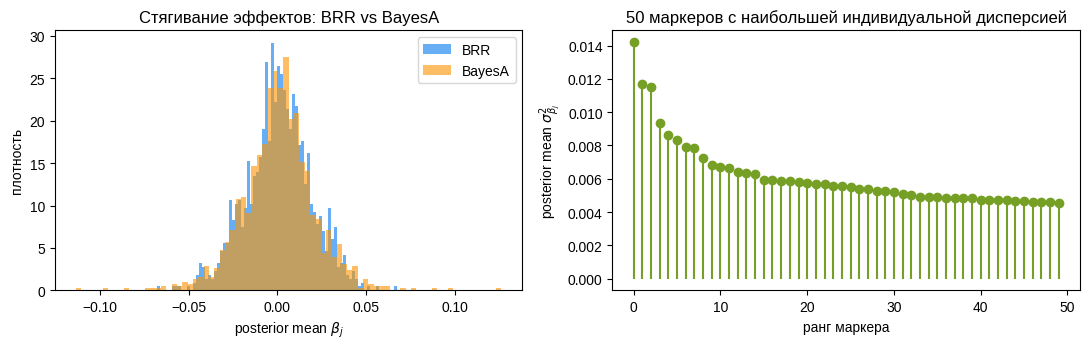

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

ax = axes[0]
ax.hist(fb["beta"], bins=80, alpha=0.6, density=True, label="BRR", color="#0279EE")
ax.hist(fa["beta"], bins=80, alpha=0.6, density=True, label="BayesA", color="#FF9400")
ax.set_xlabel("posterior mean $\\beta_j$"); ax.set_ylabel("плотность")
ax.legend(); ax.set_title("Стягивание эффектов: BRR vs BayesA")

ax = axes[1]
s2bj = fa["sigma2_bj"]
order = np.argsort(s2bj)[::-1]
ax.stem(np.arange(50), s2bj[order[:50]], linefmt="#75A025", markerfmt="o", basefmt=" ")
ax.set_xlabel("ранг маркера"); ax.set_ylabel("posterior mean $\\sigma^2_{\\beta_j}$")
ax.set_title("50 маркеров с наибольшей индивидуальной дисперсией")
plt.tight_layout()
plt.savefig(FIGDIR / "bayesa_vs_brr.png", dpi=150)
plt.savefig(FIGDIR / "bayesa_vs_brr.svg")
plt.show()

## Что тут важно

- BayesA — это BRR с вектором дисперсий вместо одного скаляра. Расплата —
  p лишних параметров σ²_βj: MCMC смешивается медленнее, итераций нужно
  больше.
- Индивидуальные σ²_βj показывают «крупные» маркеры (правый график) —
  своего рода отбор маркеров внутри модели.
- Дальше (05): честное сравнение точности всех трёх моделей в
  кросс-валидации.